# Experiment 6: K-Means Clustering
Run the cells from top to bottom.

In [1]:
# Clustering is a technique in machine learning used to divide a group of data points into smaller groups based on their similarities and characteristics. 
# It helps in identifying hidden patterns and relationships within a dataset.

#K-Means Clustering is an unsupervised machine learning algorithm used to divide a dataset into K distinct groups called clusters.
# The main objective of this algorithm is to group data points that are similar to each other while keeping dissimilar data points in different clusters.
# It works by calculating the distance between data points and their cluster centroids, generally using Euclidean distance.

# The K-Means algorithm works through the following steps:
# 1. Initialize Centroids: Select K random points from the dataset as initial cluster centroids.
# 2. Assign Clusters: Assign each data point to the nearest centroid based on distance.
# 3. Update Centroids: Calculate the mean of all data points belonging to each cluster to obtain new centroids.
# 4. Repeat: Repeat the assignment and centroid update steps until the centroids stop changing significantly or the algorithm reaches its maximum iterations.

# K-Means is simple, efficient and widely used in customer segmentation, image compression, document grouping and pattern recognition. 
# However, the value of K must be specified in advance, and the algorithm can be affected by outliers and the initial selection of centroids. 
# Standardization is often performed before clustering to ensure that features with larger numerical values do not dominate the results.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [3]:
# Generate Chess Dataset
np.random.seed(42)
n = 1000
df = pd.DataFrame({
    'Elo_Rating': np.random.randint(2400, 2880, n),
    'Rapid_Rating': np.random.randint(2300, 2850, n),
    'Blitz_Rating': np.random.randint(2300, 2900, n),
    'Wins': np.random.randint(0, 15, n),
    'Draws': np.random.randint(2, 20, n),
    'Losses': np.random.randint(0, 10, n)
})
df['Total_Games'] = df['Wins'] + df['Draws'] + df['Losses']
df['Win_Ratio'] = df['Wins'] / df['Total_Games']

In [4]:
# Select and standardize features
X = StandardScaler().fit_transform(df[['Elo_Rating', 'Win_Ratio']])

In [5]:
# Apply K-Means Clustering
km = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = km.fit_predict(X)
centers = km.cluster_centers_
print("Cluster Labels:", labels[:50])
print("Centroids:\n", centers)

Cluster Labels: [0 1 2 2 0 2 0 2 2 2 1 0 1 1 0 2 2 1 0 2 0 1 2 1 1 2 1 0 1 2 2 1 1 0 2 2 2
 0 1 0 0 1 2 2 2 2 1 0 1 2]
Centroids:
 [[-0.84595017 -0.75585696]
 [ 1.03586742 -0.28003095]
 [-0.39597569  0.94723099]]


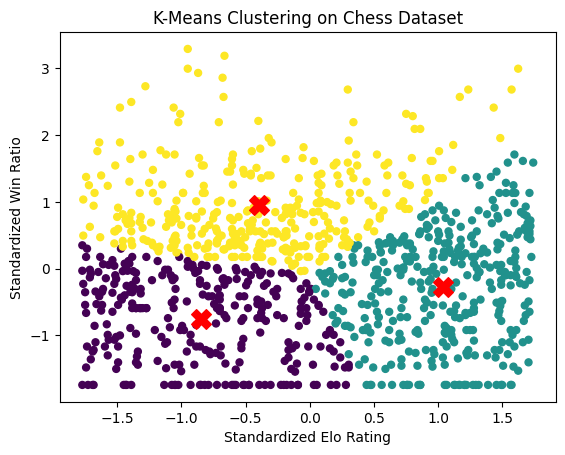

In [6]:
# Visualize Clusters
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=25)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200)
plt.xlabel("Standardized Elo Rating")
plt.ylabel("Standardized Win Ratio")
plt.title("K-Means Clustering on Chess Dataset")
plt.show()